# Задание 2.6
## Корни многочлена 11-й степени

### Условие:
Для многочлена
$$
p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2
$$
найдите все 11 корней $z_1,\dots,z_{11}\in\mathbb C$. В ответе укажите: 1) сумму модулей $|z_1|+\dots+|z_{11}|$; 2) действительную часть корня, у которого она максимальна.

### Идея решения:
По основной теореме алгебры многочлен степени 11 имеет ровно 11 комплексных корней с учётом кратности. Коэффициенты вещественные, поэтому невещественные корни разбиваются на пары сопряжённых; так как степень нечётная, хотя бы один корень вещественный. Формулы для корней многочленов степени выше 4 в радикалах в общем случае не существует, поэтому найдём корни численно (собственные значения сопровождающей матрицы), а затем проверим результат подстановкой, соотношениями Виета и вычислением с повышенной точностью.

### Проверка неприводимости над $\mathbb Q$ (`sympy`)

In [1]:
import sympy as sp

x = sp.symbols('x')
p = x**11 + x**10 + x**8 - 2*x**7 - x**5 + x**4 + 2*x**2 + 2*x + 2
print('разложение над Q:', sp.factor_list(p))
print('рациональные корни:', sp.Poly(p, x).ground_roots())

разложение над Q: (1, [(x**11 + x**10 + x**8 - 2*x**7 - x**5 + x**4 + 2*x**2 + 2*x + 2, 1)])
рациональные корни: {}


### Численное нахождение корней

In [2]:
import numpy as np

# коэффициенты при x^11, x^10, ..., x^0 (отсутствующие степени — нули)
coef = [1, 1, 0, 1, -2, 0, -1, 1, 0, 2, 2, 2]
roots = np.roots(coef)
roots = roots[np.lexsort((-roots.imag, -roots.real))]   # по убыванию Re

print('количество корней:', len(roots))
print(' №            Re z           Im z         |z|')
for i, z in enumerate(roots, 1):
    print(f'{i:2d}   {z.real: .10f}  {z.imag: .10f}   {abs(z):.10f}')

количество корней: 11
 №            Re z           Im z         |z|
 1    1.0806017374   0.3238931188   1.1280987843
 2    1.0806017374  -0.3238931188   1.1280987843
 3    0.4777545236   0.9010752305   1.0198950710
 4    0.4777545236  -0.9010752305   1.0198950710
 5   -0.0125001806   1.1826990817   1.1827651383
 6   -0.0125001806  -1.1826990817   1.1827651383
 7   -0.4500371127   0.8039231442   0.9213174397
 8   -0.4500371127  -0.8039231442   0.9213174397
 9   -0.7074344552   0.4643747259   0.8462312890
10   -0.7074344552  -0.4643747259   0.8462312890
11   -1.7767690249   0.0000000000   1.7767690249


### Проверка: невязка, формулы Виета и расчёт с высокой точностью (`mpmath`)

In [3]:
import mpmath as mp

pol = np.poly1d(coef)
print('max |p(z_k)|            =', np.max(np.abs(pol(roots))))
print('сумма корней (Виета: −1)  =', np.round(roots.sum(), 10))
print('произведение (Виета: −2)  =', np.round(np.prod(roots), 10))

mp.mp.dps = 30
exact = mp.polyroots(coef, maxsteps=500, extraprec=200)
print('сумма модулей (mpmath)  =', mp.nstr(sum(abs(z) for z in exact), 15))
print('max Re (mpmath)         =', mp.nstr(max(z.real for z in exact), 15))

max |p(z_k)|            = 1.6484591469634324e-12
сумма корней (Виета: −1)  = (-1+0j)
произведение (Виета: −2)  = (-2-0j)
сумма модулей (mpmath)  = 11.9733844697121
max Re (mpmath)         = 1.08060173735785


### Ответы на вопросы задачи

In [4]:
S = np.abs(roots).sum()
best = roots[np.argmax(roots.real)]
print(f'1) сумма модулей           = {S:.8f}')
print(f'2) максимальная Re z_k     = {best.real:.8f}   (корни {best.real:.6f} ± {abs(best.imag):.6f}i)')
print('вещественные корни:', roots[np.abs(roots.imag) < 1e-9].real)

1) сумма модулей           = 11.97338447
2) максимальная Re z_k     = 1.08060174   (корни 1.080602 ± 0.323893i)
вещественные корни: [-1.77676902]


### Корни на комплексной плоскости

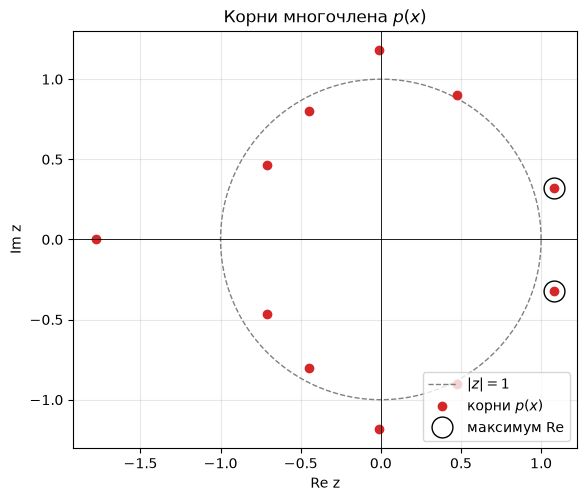

In [5]:
import matplotlib.pyplot as plt

t = np.linspace(0, 2*np.pi, 400)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(np.cos(t), np.sin(t), '--', color='gray', lw=1, label='$|z|=1$')
ax.plot(roots.real, roots.imag, 'o', color='tab:red', label='корни $p(x)$')
top = roots[np.isclose(roots.real, roots.real.max())]
ax.plot(top.real, top.imag, 'o', mfc='none', mec='k', ms=15, label='максимум Re')
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
ax.set_aspect('equal'); ax.grid(alpha=0.3)
ax.set_xlabel('Re z'); ax.set_ylabel('Im z'); ax.set_title('Корни многочлена $p(x)$')
ax.legend(loc='lower right')
plt.show()

### Ответ:

Многочлен неприводим над $\mathbb Q$, корни найдены численно: один вещественный $z\approx-1{,}77677$ и пять пар комплексно-сопряжённых
$1{,}08060\pm0{,}32389i,\ 0{,}47775\pm0{,}90108i,\ -0{,}01250\pm1{,}18270i,\ -0{,}45004\pm0{,}80392i,\ -0{,}70743\pm0{,}46437i$.

1) $\displaystyle\sum_{k=1}^{11}|z_k|\approx\mathbf{11{,}97338}$;

2) максимальная действительная часть: $\operatorname{Re}z\approx\mathbf{1{,}08060}$ (корни $1{,}08060\pm0{,}32389i$).